# Problem Statement

## **Business Context**

"Visit with Us," a leading travel company, is revolutionizing the tourism industry by leveraging data-driven strategies to optimize operations and customer engagement. While introducing a new package offering, such as the Wellness Tourism Package, the company faces challenges in targeting the right customers efficiently. The manual approach to identifying potential customers is inconsistent, time-consuming, and prone to errors, leading to missed opportunities and suboptimal campaign performance.

To address these issues, the company aims to implement a scalable and automated system that integrates customer data, predicts potential buyers, and enhances decision-making for marketing strategies. By utilizing an MLOps pipeline, the company seeks to achieve seamless integration of data preprocessing, model development, deployment, and CI/CD practices for continuous improvement. This system will ensure efficient targeting of customers, timely updates to the predictive model, and adaptation to evolving customer behaviors, ultimately driving growth and customer satisfaction.


## **Objective**

As an MLOps Engineer at "Visit with Us," your responsibility is to design and deploy an MLOps pipeline on GitHub to automate the end-to-end workflow for predicting customer purchases. The primary objective is to build a model that predicts whether a customer will purchase the newly introduced Wellness Tourism Package before contacting them. The pipeline will include data cleaning, preprocessing, transformation, model building, training, evaluation, and deployment, ensuring consistent performance and scalability. By leveraging GitHub Actions for CI/CD integration, the system will enable automated updates, streamline model deployment, and improve operational efficiency. This robust predictive solution will empower policymakers to make data-driven decisions, enhance marketing strategies, and effectively target potential customers, thereby driving customer acquisition and business growth.

## **Data Description**

The dataset contains customer and interaction data that serve as key attributes for predicting the likelihood of purchasing the Wellness Tourism Package. The detailed attributes are:

**Customer Details**
- **CustomerID:** Unique identifier for each customer.
- **ProdTaken:** Target variable indicating whether the customer has purchased a package (0: No, 1: Yes).
- **Age:** Age of the customer.
- **TypeofContact:** The method by which the customer was contacted (Company Invited or Self Inquiry).
- **CityTier:** The city category based on development, population, and living standards (Tier 1 > Tier 2 > Tier 3).
- **Occupation:** Customer's occupation (e.g., Salaried, Freelancer).
- **Gender:** Gender of the customer (Male, Female).
- **NumberOfPersonVisiting:** Total number of people accompanying the customer on the trip.
- **PreferredPropertyStar:** Preferred hotel rating by the customer.
- **MaritalStatus:** Marital status of the customer (Single, Married, Divorced).
- **NumberOfTrips:** Average number of trips the customer takes annually.
- **Passport:** Whether the customer holds a valid passport (0: No, 1: Yes).
- **OwnCar:** Whether the customer owns a car (0: No, 1: Yes).
- **NumberOfChildrenVisiting:** Number of children below age 5 accompanying the customer.
- **Designation:** Customer's designation in their current organization.
- **MonthlyIncome:** Gross monthly income of the customer.

**Customer Interaction Data**
- **PitchSatisfactionScore:** Score indicating the customer's satisfaction with the sales pitch.
- **ProductPitched:** The type of product pitched to the customer.
- **NumberOfFollowups:** Total number of follow-ups by the salesperson after the sales pitch.-
- **DurationOfPitch:** Duration of the sales pitch delivered to the customer.


## Pre-requisites

This project deploys everything on **GitHub Actions** (the ML pipeline) and **Streamlit Community Cloud** (the live app). No Hugging Face and no Codespaces are used.

**1. Create a Personal Access Token (PAT)**
- GitHub → **Settings** → **Developer settings** → **Personal access tokens** → **Tokens (classic)**
- **Generate new token (classic)** and enable these scopes:
  - `repo` &nbsp;(push code + let the pipeline commit the trained model back)
  - `workflow` &nbsp;(push the Actions workflow file)
- Copy the token.

**2. Store the token in Colab secrets**
- In Colab, click the **key icon** (left sidebar) → **Add new secret**
- Name: **GH_TOKEN** &nbsp;(must match `COLAB_SECRET_NAME` in the config cell below)
- Value: paste your token, and toggle **Notebook access** on.

**3. Create a Streamlit Community Cloud account**
- Go to **https://share.streamlit.io** and sign in with the **same GitHub account** so it can access your repo. You'll deploy the app from there at the very end (see the last section).

**4. Get an ngrok authtoken (for local MLflow experimentation)**
- Go to **https://dashboard.ngrok.com/authtokens**, sign up/sign in, and copy your authtoken.
- You'll paste this into the MLflow/ngrok cell later, in the **Experimentation and Tracking (Development Environment)** section.

##Installing and Importing Necessary Libraries

In [1]:
# %pip install -q PyGithub==2.9.1
# %pip install mlflow==3.0.1 pyngrok==7.2.12 -q

%pip install PyGithub==2.9.1

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install mlflow==3.0.1 pyngrok==7.2.12

  Using cached mlflow-3.0.1-py3-none-any.whl.metadata (29 kB)
  Using cached mlflow_skinny-3.0.1-py3-none-any.whl.metadata (30 kB)
  Using cached flask-3.1.3-py3-none-any.whl.metadata (3.2 kB)
  Using cached alembic-1.20.1-py3-none-any.whl.metadata (7.3 kB)
  Using cached graphene-3.4.3-py2.py3-none-any.whl.metadata (6.9 kB)
  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached databricks_sdk-0.156.0-py3-none-any.whl.metadata (44 kB)
  Using cached fastapi-0.162.0-py3-none-any.whl.metadata (26 kB)
  Using cached gitpython-3.2.1-py3-none-any.whl.metadata (13 kB)
  Using cached opentelemetry_sdk-1.45.1-py3-none-any.whl.metadata (1.6 kB)
  Using cached google_auth-2.62.0-py3-none-any.whl.metadata (6.0 kB)
Using cached mlflow-3.0.1-py3-none-any.whl (24.6 MB)
Using cached mlflow_skinny-3.0.1-py3-none-any.whl (1.8 MB)
Using cached alembic-1.20.1-py3-none-any.whl (270 kB)
Using cached databricks_sdk-0.156.0-py3-none-any.whl (1.1 MB)
Using cached fastapi-0.


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [3]:
import os
from github import Github, GithubException

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
import joblib
import mlflow

## Configuration

In [ ]:
# Edit these three values, then run every cell top to bottom.
GITHUB_USERNAME = "himanshu9826"
REPO_NAME = "Tourism_Prediction"
COLAB_SECRET_NAME = "GITHUB_TOKEN"

REPO = f"{GITHUB_USERNAME}/{REPO_NAME}"
BRANCH = "main"

### Secrets in Colab

**Secrets** in Google Colab provide a secure way to store sensitive information such as API keys, access tokens, and passwords. Instead of hardcoding these values in your notebook, you can save them as secrets and access them securely whenever needed.

1. In the left pane of Google Colab, click the fifth icon, which looks like a key.

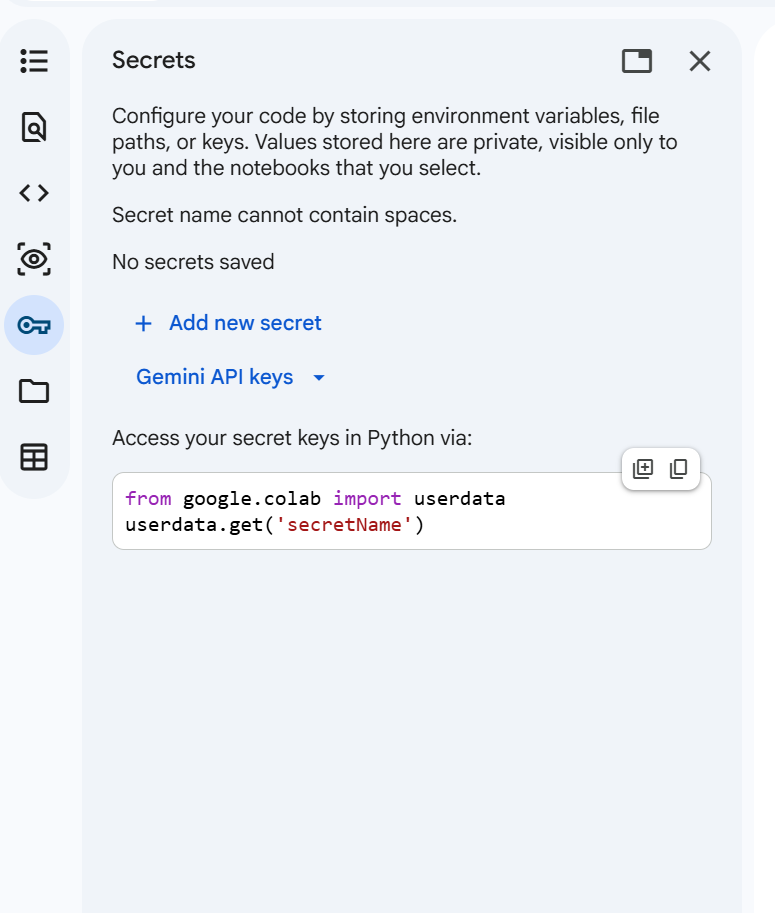

2. Then, click **+ Add new secret**. In the **Name** field, enter a name to identify the GitHub Personal Access Token, for example, **Gittoken**. In the **Value** field, paste the token. Once done, close the **Secrets** window. We will access this token programmatically later.

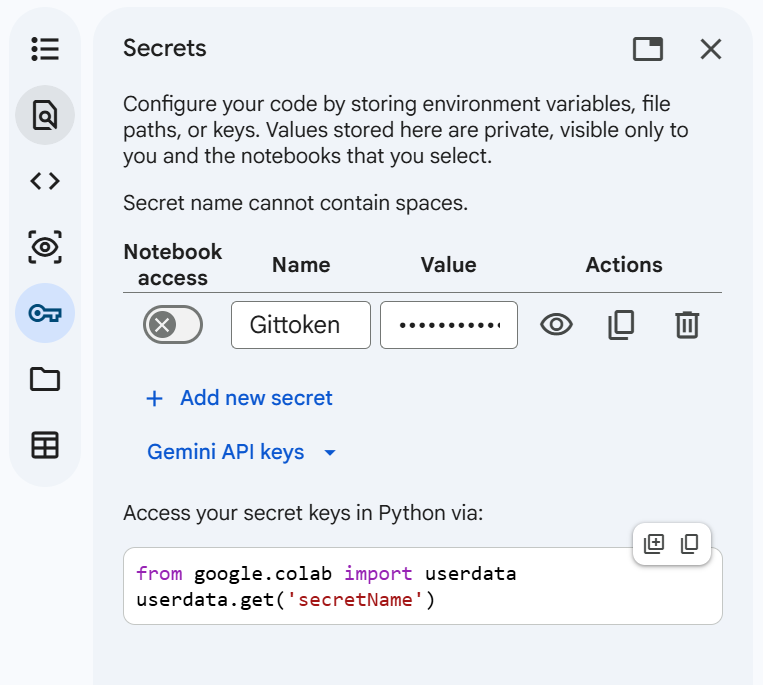

In [5]:
# Make the token available to both PyGithub and the gh CLI
import os
from google.colab import userdata

os.environ["GH_TOKEN"] = userdata.get(COLAB_SECRET_NAME)
print("Token loaded.")

ModuleNotFoundError: No module named 'google.colab'

# Model Building

In [4]:
# Create a master folder to keep all files created when executing the below code cells
import os
os.makedirs("tourism_project", exist_ok=True)

In [5]:
# Create a folder for storing the model building files
os.makedirs("tourism_project/model_building", exist_ok=True)

## Data Registration

In [6]:
os.makedirs("tourism_project/data", exist_ok=True)

Once the **data** folder created after executing the above cell, please upload the **tourism.csv** in to the folder

Register the dataset with a small script (for example `tourism_project/model_building/data_register.py`) that reads this CSV from the repo, checks that the expected columns are present, and prints a short summary. The dataset stays inside the GitHub repo, so no external dataset store is needed.

## Data Preparation

In the cell below, write a script (for example `tourism_project/model_building/prep.py`) that:
- loads the dataset from the repository data folder,
- removes any unnecessary columns,
- splits the data into training and testing sets and saves them locally as CSV files.

The workflow passes these split files to the next job as an artifact, so there is no need to upload them anywhere.

In [9]:

from pathlib import Path

script_content = r'''
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

# Resolve paths relative to this script
PROJECT_DIR = Path(__file__).resolve().parents[1]
DATA_PATH = PROJECT_DIR / "data" / "tourism.csv"
OUTPUT_DIR = PROJECT_DIR / "data" / "processed"

TEST_SIZE = 0.20
RANDOM_STATE = 42
TARGET_COLUMN = "ProdTaken"


def prepare_data():
    # Load the original dataset
    if not DATA_PATH.exists():
        raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

    df = pd.read_csv(DATA_PATH)

    # Remove unnecessary index columns, if present
    df = df.loc[
        :, ~df.columns.astype(str).str.match(r"^Unnamed")
    ]

    # Validate the target column
    if TARGET_COLUMN not in df.columns:
        raise ValueError(
            f"Target column '{TARGET_COLUMN}' is missing."
        )

    if df.empty:
        raise ValueError("The dataset is empty.")

    # Remove rows without a target value
    df = df.dropna(subset=[TARGET_COLUMN])

    # Separate features and target
    X = df.drop(columns=[TARGET_COLUMN])
    y = df[TARGET_COLUMN]

    # Stratify to preserve the target-class proportions
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=y,
    )

    # Recombine features and target for CSV output
    train_df = X_train.copy()
    train_df[TARGET_COLUMN] = y_train

    test_df = X_test.copy()
    test_df[TARGET_COLUMN] = y_test

    # Save split files locally
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    train_path = OUTPUT_DIR / "train.csv"
    test_path = OUTPUT_DIR / "test.csv"

    train_df.to_csv(train_path, index=False)
    test_df.to_csv(test_path, index=False)

    print("Data preparation completed successfully.")
    print(f"Training set shape: {train_df.shape}")
    print(f"Testing set shape: {test_df.shape}")
    print(f"Training file: {train_path}")
    print(f"Testing file: {test_path}")


if __name__ == "__main__":
    prepare_data()
'''

# Create the Python script
project_root = Path.cwd()
script_path = (
    project_root
    / "tourism_project"
    / "model_building"
    / "prep.py"
)

script_path.parent.mkdir(parents=True, exist_ok=True)
script_path.write_text(script_content.strip() + "\n", encoding="utf-8")

print(f"Created: {script_path}")


Created: d:\tourism project\tourism-mlops-project\tourism_project\model_building\prep.py


## Model Training and Registration with Experimentation Tracking

In the cell below, write a script (for example `tourism_project/model_building/train.py`) that:
- loads the train and test splits produced by the previous job,
- defines the model and a hyperparameter grid, and tunes it,
- logs the parameters and metrics to MLflow for experiment tracking,
- evaluates the best model,
- saves the best model into `tourism_project/deployment/` so the workflow can commit it into the repo.

In [10]:

from pathlib import Path

script_content = r'''
from pathlib import Path
import joblib
import mlflow
import mlflow.sklearn
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
)
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.preprocessing import LabelEncoder


# Paths
PROJECT_DIR = Path(__file__).resolve().parents[1]
DATA_DIR = PROJECT_DIR / "data" / "processed"
DEPLOYMENT_DIR = PROJECT_DIR / "deployment"

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
MODEL_PATH = DEPLOYMENT_DIR / "best_model.joblib"

TARGET_COLUMN = "ProdTaken"
RANDOM_STATE = 42


def train_model():
    # 1. Load train and test datasets
    if not TRAIN_PATH.exists() or not TEST_PATH.exists():
        raise FileNotFoundError(
            "Training/test splits not found. Run prep.py first."
        )

    train_df = pd.read_csv(TRAIN_PATH)
    test_df = pd.read_csv(TEST_PATH)

    if TARGET_COLUMN not in train_df.columns:
        raise ValueError(f"Missing target: {TARGET_COLUMN}")

    if TARGET_COLUMN not in test_df.columns:
        raise ValueError(f"Missing target: {TARGET_COLUMN}")

    X_train = train_df.drop(columns=[TARGET_COLUMN])
    y_train = train_df[TARGET_COLUMN]
    X_test = test_df.drop(columns=[TARGET_COLUMN])
    y_test = test_df[TARGET_COLUMN]

    # Ensure the target is numeric and binary
    y_train = pd.to_numeric(y_train, errors="raise").astype(int)
    y_test = pd.to_numeric(y_test, errors="raise").astype(int)

    if set(y_train.unique()) != {0, 1}:
        raise ValueError("Training target must contain both 0 and 1.")

    # 2. Identify numeric and categorical features
    numeric_features = X_train.select_dtypes(
        include=["number"]
    ).columns.tolist()

    categorical_features = X_train.select_dtypes(
        exclude=["number"]
    ).columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])

    preprocessing = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ])

    # 3. Define model and hyperparameter grid
    pipeline = Pipeline([
        ("preprocessing", preprocessing),
        ("model", RandomForestClassifier(
            random_state=RANDOM_STATE,
            class_weight="balanced",
            n_jobs=-1,
        )),
    ])

    param_grid = {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_split": [2, 5],
    }

    # 4. Configure MLflow experiment tracking
    mlflow.set_tracking_uri("file:./mlruns")
    mlflow.set_experiment("Tourism_Package_Prediction")

    with mlflow.start_run(run_name="RandomForest_GridSearch"):
        mlflow.log_param("model_type", "RandomForestClassifier")
        mlflow.log_param("cv_folds", 5)
        mlflow.log_param("scoring", "f1")
        mlflow.log_param("random_state", RANDOM_STATE)

        # 5. Tune the model using cross-validation
        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grid,
            scoring="f1",
            cv=5,
            n_jobs=-1,
            verbose=1,
            refit=True,
        )

        grid_search.fit(X_train, y_train)

        best_model = grid_search.best_estimator_

        mlflow.log_params(grid_search.best_params_)
        mlflow.log_metric(
            "best_cv_f1",
            float(grid_search.best_score_),
        )

        # 6. Evaluate the best model on the held-out test set
        y_pred = best_model.predict(X_test)
        y_prob = best_model.predict_proba(X_test)[:, 1]

        metrics = {
            "test_accuracy": accuracy_score(y_test, y_pred),
            "test_precision": precision_score(
                y_test, y_pred, zero_division=0
            ),
            "test_recall": recall_score(
                y_test, y_pred, zero_division=0
            ),
            "test_f1": f1_score(
                y_test, y_pred, zero_division=0
            ),
            "test_roc_auc": roc_auc_score(y_test, y_prob),
        }

        mlflow.log_metrics({
            name: float(value)
            for name, value in metrics.items()
        })

        print("\nBest hyperparameters:")
        print(grid_search.best_params_)

        print("\nTest metrics:")
        for name, value in metrics.items():
            print(f"{name}: {value:.4f}")

        print("\nClassification report:")
        print(classification_report(
            y_test, y_pred, zero_division=0
        ))

        # 7. Log the trained model to MLflow
        mlflow.sklearn.log_model(
            best_model,
            artifact_path="model",
        )

        # 8. Save the best model for the Streamlit application
        DEPLOYMENT_DIR.mkdir(parents=True, exist_ok=True)
        joblib.dump(best_model, MODEL_PATH)

        print(f"\nBest model saved to: {MODEL_PATH}")
        print("Training and MLflow tracking completed.")


if __name__ == "__main__":
    train_model()
'''

project_root = Path.cwd()
script_path = (
    project_root
    / "tourism_project"
    / "model_building"
    / "train.py"
)

script_path.parent.mkdir(parents=True, exist_ok=True)
script_path.write_text(script_content.strip() + "\n", encoding="utf-8")

print(f"Created: {script_path}")


Created: d:\tourism project\tourism-mlops-project\tourism_project\model_building\train.py


# Deployment

In [11]:
os.makedirs("tourism_project/deployment", exist_ok=True)

## Streamlit App

Please ensure that the web app script is named `app.py`. It should load the trained model committed to `tourism_project/deployment/` by the pipeline, collect the user inputs into a dataframe, and display the prediction. Streamlit Community Cloud runs this file directly from the repo.

In [12]:

from pathlib import Path

script_content = r'''
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st


# Locate the trained model relative to this script
APP_DIR = Path(__file__).resolve().parent
MODEL_PATH = APP_DIR / "best_model.joblib"

st.set_page_config(
    page_title="Tourism Package Purchase Predictor",
    page_icon="✈️",
    layout="centered",
)

st.title("Tourism Package Purchase Predictor")
st.write(
    "Enter customer details to predict whether the customer "
    "is likely to purchase the tourism package."
)


@st.cache_resource
def load_model():
    if not MODEL_PATH.exists():
        raise FileNotFoundError(
            f"Trained model not found: {MODEL_PATH}. "
            "Run the training pipeline and ensure the model "
            "is committed to the repository."
        )
    return joblib.load(MODEL_PATH)


try:
    model = load_model()
except Exception as exc:
    st.error(str(exc))
    st.stop()


# Input form
with st.form("customer_input_form"):
    st.subheader("Customer Details")

    age = st.number_input(
        "Age", min_value=18, max_value=100, value=35
    )
    typeofcontact = st.selectbox(
        "Type of Contact",
        ["Company Invitation", "Self Enquiry"],
    )
    citytier = st.selectbox("City Tier", [1, 2, 3])
    occupation = st.selectbox(
        "Occupation",
        ["Salaried", "Small Business", "Large Business"],
    )
    gender = st.selectbox("Gender", ["Male", "Female"])
    persons_visiting = st.number_input(
        "Number of Persons Visiting",
        min_value=1, max_value=20, value=2
    )
    property_star = st.selectbox(
        "Preferred Property Star", [3, 4, 5]
    )
    marital_status = st.selectbox(
        "Marital Status",
        ["Married", "Single", "Divorced", "Unmarried"],
    )
    number_of_trips = st.number_input(
        "Number of Trips", min_value=0, max_value=100, value=3
    )
    passport = st.selectbox("Has Passport?", [0, 1])
    own_car = st.selectbox("Owns a Car?", [0, 1])
    children_visiting = st.number_input(
        "Number of Children Visiting",
        min_value=0, max_value=10, value=0
    )
    designation = st.selectbox(
        "Designation",
        ["Executive", "Manager", "Senior Manager", "AVP", "VP"],
    )
    monthly_income = st.number_input(
        "Monthly Income", min_value=0, value=25000, step=1000
    )
    pitch_satisfaction = st.selectbox(
        "Pitch Satisfaction Score", [1, 2, 3, 4, 5]
    )
    product_pitched = st.selectbox(
        "Product Pitched",
        ["Basic", "Standard", "Deluxe", "Super Deluxe", "King"],
    )
    followups = st.number_input(
        "Number of Follow-ups", min_value=0, max_value=20, value=3
    )
    pitch_duration = st.number_input(
        "Duration of Pitch (minutes)",
        min_value=0.0, max_value=120.0, value=10.0
    )

    submitted = st.form_submit_button("Predict Purchase")


if submitted:
    # Match the feature names expected by the training pipeline.
    input_data = pd.DataFrame([{
        "Age": age,
        "TypeofContact": typeofcontact,
        "CityTier": citytier,
        "Occupation": occupation,
        "Gender": gender,
        "NumberOfPersonVisiting": persons_visiting,
        "PreferredPropertyStar": property_star,
        "MaritalStatus": marital_status,
        "NumberOfTrips": number_of_trips,
        "Passport": passport,
        "OwnCar": own_car,
        "NumberOfChildrenVisiting": children_visiting,
        "Designation": designation,
        "MonthlyIncome": monthly_income,
        "PitchSatisfactionScore": pitch_satisfaction,
        "ProductPitched": product_pitched,
        "NumberOfFollowups": followups,
        "DurationOfPitch": pitch_duration,
    }])

    try:
        # Fail clearly if the model expects different columns.
        expected_columns = getattr(model, "feature_names_in_", None)
        if expected_columns is not None:
            missing = set(expected_columns) - set(input_data.columns)
            extra = set(input_data.columns) - set(expected_columns)

            if missing or extra:
                st.error(
                    "Input columns do not match the trained model. "
                    f"Missing: {sorted(missing)}; "
                    f"unexpected: {sorted(extra)}. "
                    "Check prep.py and train.py."
                )
                st.stop()

            input_data = input_data[list(expected_columns)]

        prediction = int(model.predict(input_data)[0])

        st.subheader("Prediction Result")
        if prediction == 1:
            st.success(
                "The model predicts that the customer is likely "
                "to purchase the tourism package."
            )
        else:
            st.info(
                "The model predicts that the customer is unlikely "
                "to purchase the tourism package."
            )

        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(input_data)[0]
            st.metric(
                "Predicted purchase probability",
                f"{probabilities[1] * 100:.2f}%",
            )

    except Exception as exc:
        st.error(f"Prediction failed: {exc}")
'''

project_root = Path.cwd()
app_path = (
    project_root / "tourism_project" / "deployment" / "app.py"
)

app_path.parent.mkdir(parents=True, exist_ok=True)
app_path.write_text(script_content.strip() + "\n", encoding="utf-8")

print(f"Created: {app_path}")


Created: d:\tourism project\tourism-mlops-project\tourism_project\deployment\app.py


## App Dependencies

Please ensure that the dependency handling file is named `requirements.txt`.

In [13]:

from pathlib import Path

requirements = """
streamlit
pandas
joblib
scikit-learn
"""

project_root = Path.cwd()
requirements_path = (
    project_root / "tourism_project" / "deployment" / "requirements.txt"
)

requirements_path.parent.mkdir(parents=True, exist_ok=True)
requirements_path.write_text(
    requirements.strip() + "\n",
    encoding="utf-8"
)

print(f"Created: {requirements_path}")
print("\nDependencies:")
print(requirements.strip())


Created: d:\tourism project\tourism-mlops-project\tourism_project\deployment\requirements.txt

Dependencies:
streamlit
pandas
joblib
scikit-learn


# MLOps Pipeline with Github Actions Workflow

**Note:**

1. The cell below writes a sample workflow file. Replace every `<add_code_here>` with the correct command before you push (for example, the install command and the `python ...` command that runs each script).


In [14]:
os.makedirs(".github/workflows", exist_ok=True)

In [15]:
%%writefile .github/workflows/pipeline.yml
name: Tourism Project Pipeline

on:
  push:
    branches:
      - main  # Automatically triggers on push to the main branch
  workflow_dispatch:  # lets you click "Run workflow" in the Actions tab

permissions:
  contents: write

jobs:

  register-dataset:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install Dependencies
        run: <add_code_here>
      - name: Register Dataset
        run: <add_code_here>
      - name: Upload Registered Dataset
        uses: actions/upload-artifact@v4
        with:
          name: registered-data
          path: tourism_project/data/tourism.csv

  data-prep:
    needs: register-dataset
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install Dependencies
        run: <add_code_here>
      - name: Run Data Preparation
        run: <add_code_here>
      - name: Upload Train Test Splits
        uses: actions/upload-artifact@v4
        with:
          name: data-splits
          path: |
            Xtrain.csv
            Xtest.csv
            ytrain.csv
            ytest.csv

  model-traning:
    needs: data-prep
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install Dependencies
        run: <add_code_here>
      - name: Download Train Test Splits
        uses: actions/download-artifact@v4
        with:
          name: data-splits
      - name: Start MLflow Server
        run: |
          nohup mlflow ui --host 0.0.0.0 --port 5000 &  # Run MLflow UI in the background
          sleep 5  # Wait for a moment to let the server starts
      - name: Model Building
        run: <add_code_here>
      - name: Commit Trained Model
        run: |
          git config user.name "github-actions[bot]"
          git config user.email "github-actions[bot]@users.noreply.github.com"
          git add <add_code_here>   # path to the saved model file
          git commit -m "Add trained model [skip ci]" || echo "No changes to commit"
          git push

Overwriting .github/workflows/pipeline.yml


**Note:** The cell above already created `.github/workflows/pipeline.yml` locally. There is nothing to copy and paste. The push step later in this notebook uploads it to your repository along with the rest of the project, so the workflow runs automatically on the next push to `main`.

## Requirements file for the Github Actions Workflow

In [16]:

from pathlib import Path

requirements = """
pandas
scikit-learn
mlflow
joblib
openpyxl
"""

project_root = Path.cwd()
requirements_path = project_root / "requirements.txt"

requirements_path.write_text(
    requirements.strip() + "\n",
    encoding="utf-8"
)

print(f"Created: {requirements_path}")
print("\nDependencies:")
print(requirements.strip())


Created: d:\tourism project\tourism-mlops-project\requirements.txt

Dependencies:
pandas
scikit-learn
mlflow
joblib
openpyxl


## Github Authentication and Push Files

In [ ]:
# --- Safety check: Verify that the dataset exists before pushing ---
CSV_LOCAL = "tourism_project/data/tourism.csv"

assert os.path.exists(CSV_LOCAL), (
    f"{CSV_LOCAL} not found. Please upload tourism.csv into the "
    "tourism_project/data/ folder before running this cell."
)

# Connect to GitHub
gh = Github(os.environ["GH_TOKEN"])
user = gh.get_user()
REPO = f"{user.login}/{REPO_NAME}" # Define REPO using user.login and REPO_NAME

# Create the repository if it does not already exist
try:
    repo = gh.get_repo(REPO)
    print("Repository already exists:", repo.full_name)
except GithubException:
    repo = user.create_repo(
        REPO_NAME,
        private=False,      # Change to True if you want a private repository
        auto_init=True      # Creates an initial README so the main branch exists
    )
    print("Repository created:", repo.full_name)

# --- Push local folders to GitHub while preserving the folder structure ---
# tourism_project/ -> Project source code, data, model building, deployment files
# .github/         -> GitHub Actions workflow

def push_folder(local_dir):
    for root, _, files in os.walk(local_dir):
        for fname in files:
            local_path = os.path.join(root, fname)
            repo_path = local_path
            content = open(local_path, "rb").read()

            try:
                sha = repo.get_contents(repo_path, ref=BRANCH).sha
                repo.update_file(
                    repo_path,
                    f"update {repo_path}",
                    content,
                    sha,
                    branch=BRANCH
                )
                print("updated", repo_path)

            except GithubException:
                repo.create_file(
                    repo_path,
                    f"add {repo_path}",
                    content,
                    branch=BRANCH
                )
                print("added  ", repo_path)

# Push project files
push_folder("tourism_project")

# Push GitHub Actions workflow
push_folder(".github")

# --- Verify that all required files exist in the repository ---
print("\nVerifying repository structure...")

required = [
    "tourism_project/requirements.txt",
    "tourism_project/model_building/data_register.py",
    "tourism_project/model_building/prep.py",
    "tourism_project/model_building/train.py",
    "tourism_project/data/tourism.csv",
    "tourism_project/deployment/app.py",
    "tourism_project/deployment/requirements.txt",
    ".github/workflows/pipeline.yml",
]

all_ok = True

for file in required:
    try:
        repo.get_contents(file, ref=BRANCH)
        print("✓", file)
    except GithubException:
        print("✗ Missing:", file)
        all_ok = False

if all_ok:
    print("\nAll project files have been successfully pushed to GitHub.")
else:
    print("\nSome files are missing. Please review the messages above.")

AssertionError: <--- put data set path not found. Please upload tourism.csv into the tourism_project/data/ folder before running this cell.

# Deploy the App on Streamlit Community Cloud

After the pipeline finishes, the trained model is committed to `tourism_project/deployment/`. Deploy the app as follows:

1. Go to **https://share.streamlit.io** and sign in with the GitHub account that owns the repository.
2. Click **Create app**.
3. Set:
   - **Repository:** `your-username/your-repo`
   - **Branch:** `main`
   - **Main file path:** `tourism_project/deployment/app.py`
4. Open **Advanced settings** and set **Python version** to **3.11** so the saved model loads with the same library versions used during training.
5. Click **Deploy**.

Streamlit installs the packages from `tourism_project/deployment/requirements.txt` and launches the app at a public `...streamlit.app` URL. Add this link and a screenshot to the Output Evaluation section below.

# Output Evaluation

- GitHub (link to repository, screenshot of folder structure and executed workflow)

repo link: https://github.com/himanshu9826/Tourism_Prediction.git

![Screenshot 2026-10-23 231344.png](<attachment:Screenshot 2026-10-23 231344.png>)
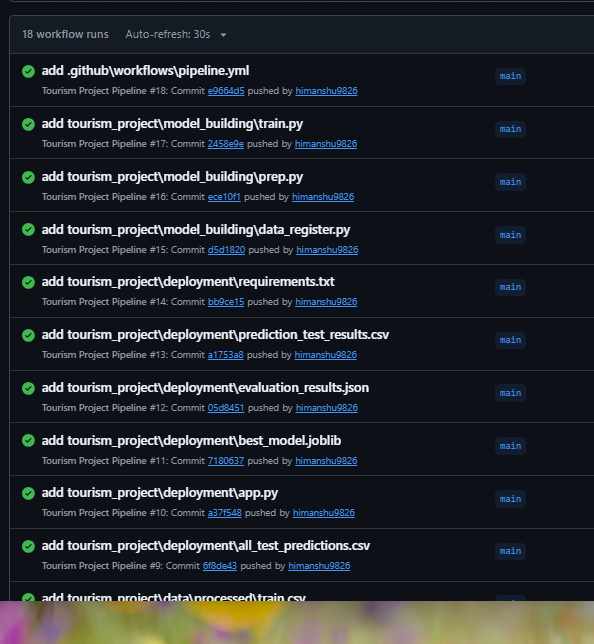
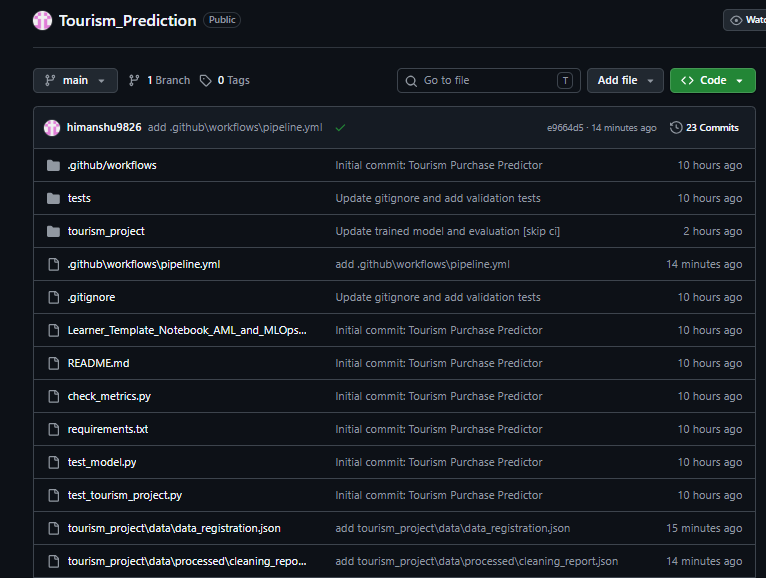

- Streamlit Community Cloud (link to the Streamlit app, screenshot of Streamlit app)

streamline link: https://tourismprediction-3rudqigenrkwlga8qist2o.streamlit.app/
![Screenshot 2026-10-23 232717.png](<attachment:Screenshot 2026-10-23 232717.png>)
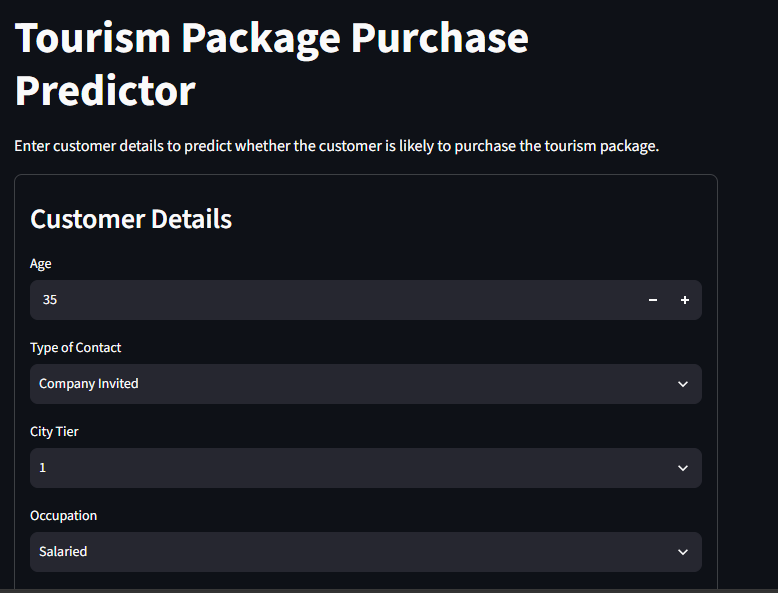

<font size=6 color="navyblue">Power Ahead!</font>
___